# Notebook 04r — XGBoost & LightGBM Multi-Horizon (REVISI)
**Basis:** `04_xgboost.ipynb` (tidak diubah). Ruang pencarian, `n_iter=25`, dan TimeSeriesSplit 3 fold sama seperti lama (`random_state=42`).

**Apa yang direvisi dan mengapa:**
- **Perbaikan kebocoran data.** Notebook lama memakai data uji (`eval_set=[(X_test, y_test)]`) untuk early stopping, sehingga jumlah pohon dipilih dengan melihat data uji. Kini **early stopping dihilangkan**: jumlah pohon (`n_estimators`) ditentukan oleh pencarian hiperparameter (TimeSeriesSplit pada data latih), dan model final dilatih pada seluruh data latih. **Data uji tidak dipakai saat pelatihan.**
- Input/output dialihkan ke `dataset/revisi/` dan `models/revisi/` (data 2 node, fitur per segmen). File prediksi memuat `segmen`, `aktual`, dan `sekarang`.

In [1]:
# -- CELL 1: Import -----------------------------------------------
import os, json, warnings, joblib, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import xgboost as xgb, lightgbm as lgb
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import randint, uniform

plt.style.use('seaborn-v0_8-whitegrid')
OUT, MOUT = 'dataset/revisi', 'models/revisi'
os.makedirs(OUT, exist_ok=True); os.makedirs(MOUT, exist_ok=True)
HORIZONS = ['60m', '180m', '360m']
TARGET_MAP = {h: f'target_{h}' for h in HORIZONS}
print('XGBoost', xgb.__version__, '| LightGBM', lgb.__version__)

def evaluasi(y_true, y_pred, label=''):
    y_true = np.asarray(y_true, dtype=float); y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_true, y_pred); rmse = float(np.sqrt(mean_squared_error(y_true, y_pred)))
    r2 = r2_score(y_true, y_pred); mape = float(np.mean(np.abs((y_true - y_pred)/(np.abs(y_true)+1e-8)))*100)
    if label: print(f'  [{label}] MAE={mae:.4f}  RMSE={rmse:.4f}  R2={r2:.4f}  MAPE={mape:.2f}%')
    return {'MAE': float(mae), 'RMSE': rmse, 'R2': float(r2), 'MAPE': mape}

def py(v):  # numpy -> python (agar bisa di-JSON)
    return v.item() if hasattr(v, 'item') else v

# -- Ruang pencarian (sama seperti lama) ----------------------------
xgb_param_dist = {
    'n_estimators': randint(200, 601), 'max_depth': randint(4, 11), 'learning_rate': uniform(0.01, 0.14),
    'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.6, 0.4), 'min_child_weight': randint(3, 11),
    'gamma': uniform(0, 0.5), 'reg_alpha': uniform(0, 0.5), 'reg_lambda': uniform(0.5, 2.0)}
lgb_param_dist = {
    'n_estimators': randint(200, 601), 'max_depth': randint(4, 11), 'learning_rate': uniform(0.01, 0.14),
    'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.6, 0.4), 'min_child_samples': randint(10, 51),
    'reg_alpha': uniform(0, 0.5), 'reg_lambda': uniform(0.5, 2.0), 'num_leaves': randint(20, 80)}
N_ITER, N_CV = 25, 3

def muat(horizon):
    target = TARGET_MAP[horizon]
    tr = pd.read_csv(f'{OUT}/data_train_{horizon}.csv', parse_dates=['waktu_pembacaan'])
    te = pd.read_csv(f'{OUT}/data_test_{horizon}.csv',  parse_dates=['waktu_pembacaan'])
    with open(f'{MOUT}/feature_cols_{horizon}.json') as f: fc = json.load(f)
    return tr, te, fc, target

def simpan_prediksi(te, target, pred, nama, horizon):
    pd.DataFrame({'waktu_pembacaan': te['waktu_pembacaan'], 'segmen': te['segmen'], 'aktual': te[target].values,
                  'sekarang': te['kelembaban_tanah_avg'].values, f'prediksi_{nama}': pred}
                 ).to_csv(f'{OUT}/prediksi_{nama}_{horizon}.csv', index=False)

XGBoost 3.4.1 | LightGBM 4.7.0


In [2]:
# -- CELL 4: XGBoost (tanpa early stopping) -------
xgb_results = {}
for horizon in HORIZONS:
    t0 = time.time()
    tr, te, fc, target = muat(horizon)
    X_tr, y_tr = tr[fc].values.astype(np.float32), tr[target].values.astype(np.float32)
    X_te, y_te = te[fc].values.astype(np.float32), te[target].values.astype(np.float32)
    print(f'\n=== XGBoost {horizon} | train={len(X_tr):,} test={len(X_te):,} ===')

    search = RandomizedSearchCV(
        XGBRegressor(tree_method='hist', random_state=42, n_jobs=-1, eval_metric='rmse', verbosity=0),
        xgb_param_dist, n_iter=N_ITER, cv=TimeSeriesSplit(n_splits=N_CV),
        scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=42, verbose=0)
    search.fit(X_tr, y_tr)                                # CV hanya memakai data latih
    best = {a: py(b) for a, b in search.best_params_.items()}
    cv_rmse = float(-search.best_score_)
    print(f'  CV-RMSE {cv_rmse:.4f} | {best}')

    model = XGBRegressor(**best, tree_method='hist', random_state=42, n_jobs=-1, eval_metric='rmse', verbosity=0)
    model.fit(X_tr, y_tr, verbose=False)                  # seluruh data latih, tanpa early stopping
    print(f'  n_estimators={best["n_estimators"]}')

    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    m_tr = evaluasi(y_tr, p_tr, f'XGB train-{horizon}'); m_te = evaluasi(y_te, p_te, f'XGB test -{horizon}')
    path = f'{MOUT}/xgb_model_{horizon}.pkl'
    joblib.dump(model, path, compress=3); model.save_model(f'{MOUT}/xgb_model_{horizon}.json')
    simpan_prediksi(te, target, p_te, 'xgb', horizon)
    xgb_results[horizon] = {'best_params': best, 'cv_rmse': cv_rmse, 'n_estimators': int(best['n_estimators']),
        'n_train': int(len(X_tr)), 'train_metrics': m_tr, 'test_metrics': m_te,
        'model_size_mb': float(os.path.getsize(path)/1e6), 'waktu_latih_detik': float(time.time()-t0)}
    print(f'  selesai {time.time()-t0:.0f} detik')
with open(f'{MOUT}/xgb_metrics_all.json', 'w') as f: json.dump(xgb_results, f, indent=2)


=== XGBoost 60m | train=82,331 test=20,583 ===


  CV-RMSE 7.3926 | {'colsample_bytree': 0.8159364365206693, 'gamma': 0.1015306123673847, 'learning_rate': 0.14199949987811736, 'max_depth': 10, 'min_child_weight': 5, 'n_estimators': 442, 'reg_alpha': 0.08061064362700221, 'reg_lambda': 2.359395304685146, 'subsample': 0.9232481518257668}


  n_estimators=442


  [XGB train-60m] MAE=0.3588  RMSE=0.7185  R2=0.9984  MAPE=0.57%
  [XGB test -60m] MAE=1.8841  RMSE=3.0496  R2=0.9476  MAPE=3.00%


  selesai 647 detik



=== XGBoost 180m | train=80,908 test=20,228 ===


... (5 outputs left out)

  CV-RMSE 11.7583 | {'colsample_bytree': 0.8989280440549523, 'gamma': 0.2698460661945399, 'learning_rate': 0.09214516319293875, 'max_depth': 4, 'min_child_weight': 6, 'n_estimators': 387, 'reg_alpha': 0.27134804157912423, 'reg_lambda': 0.7818484499495253, 'subsample': 0.9208787923016158}


  n_estimators=387


  [XGB train-360m] MAE=0.9278  RMSE=1.7226  R2=0.9908  MAPE=1.49%
  [XGB test -360m] MAE=5.3351  RMSE=7.0554  R2=0.7271  MAPE=8.27%


  selesai 58420 detik


In [3]:
# -- CELL 5: LightGBM (tanpa early stopping) ------
lgb_results = {}
for horizon in HORIZONS:
    t0 = time.time()
    tr, te, fc, target = muat(horizon)
    X_tr, y_tr = tr[fc].values.astype(np.float32), tr[target].values.astype(np.float32)
    X_te, y_te = te[fc].values.astype(np.float32), te[target].values.astype(np.float32)
    print(f'\n=== LightGBM {horizon} | train={len(X_tr):,} test={len(X_te):,} ===')

    search = RandomizedSearchCV(
        LGBMRegressor(random_state=42, n_jobs=-1, verbosity=-1),
        lgb_param_dist, n_iter=N_ITER, cv=TimeSeriesSplit(n_splits=N_CV),
        scoring='neg_root_mean_squared_error', n_jobs=-1, random_state=42, verbose=0)
    search.fit(X_tr, y_tr)
    best = {a: py(b) for a, b in search.best_params_.items()}
    cv_rmse = float(-search.best_score_)
    print(f'  CV-RMSE {cv_rmse:.4f} | {best}')

    model = LGBMRegressor(**best, random_state=42, n_jobs=-1, verbosity=-1)
    model.fit(X_tr, y_tr)                                 # seluruh data latih, tanpa early stopping
    print(f'  n_estimators={best["n_estimators"]}')

    p_tr, p_te = model.predict(X_tr), model.predict(X_te)
    m_tr = evaluasi(y_tr, p_tr, f'LGB train-{horizon}'); m_te = evaluasi(y_te, p_te, f'LGB test -{horizon}')
    path = f'{MOUT}/lgb_model_{horizon}.pkl'
    joblib.dump(model, path, compress=3)
    simpan_prediksi(te, target, p_te, 'lgb', horizon)
    lgb_results[horizon] = {'best_params': best, 'cv_rmse': cv_rmse, 'n_estimators': int(best['n_estimators']),
        'n_train': int(len(X_tr)), 'train_metrics': m_tr, 'test_metrics': m_te,
        'model_size_mb': float(os.path.getsize(path)/1e6), 'waktu_latih_detik': float(time.time()-t0)}
    print(f'  selesai {time.time()-t0:.0f} detik')
with open(f'{MOUT}/lgb_metrics_all.json', 'w') as f: json.dump(lgb_results, f, indent=2)


=== LightGBM 60m | train=82,331 test=20,583 ===


  CV-RMSE 7.0932 | {'colsample_bytree': 0.6186662652854461, 'learning_rate': 0.1463257726378043, 'max_depth': 10, 'min_child_samples': 12, 'n_estimators': 506, 'num_leaves': 26, 'reg_alpha': 0.08526206184364576, 'reg_lambda': 0.630103185970559, 'subsample': 0.9795542149013333}


  n_estimators=506


  [LGB train-60m] MAE=0.5978  RMSE=1.3003  R2=0.9948  MAPE=0.96%
  [LGB test -60m] MAE=1.9133  RMSE=3.2146  R2=0.9418  MAPE=3.04%


  selesai 1530 detik



=== LightGBM 180m | train=80,908 test=20,228 ===


... (4 outputs left out)

  CV-RMSE 11.5943 | {'colsample_bytree': 0.7088528997538541, 'learning_rate': 0.10067661687579073, 'max_depth': 4, 'min_child_samples': 22, 'n_estimators': 432, 'num_leaves': 22, 'reg_alpha': 0.0034760652655953517, 'reg_lambda': 1.5214946051551315, 'subsample': 0.7669644012595116}


  n_estimators=432


  [LGB train-360m] MAE=0.9012  RMSE=1.7029  R2=0.9910  MAPE=1.45%
  [LGB test -360m] MAE=5.2266  RMSE=6.9582  R2=0.7345  MAPE=8.22%


  selesai 7199 detik


Horizon Model             MAE    RMSE      R2    MAPE
60m     RF              1.623   2.767   0.957    2.58
60m     XGBoost         1.884   3.050   0.948    3.00
60m     LightGBM        1.913   3.215   0.942    3.04
60m     Persistensi     1.381   2.968   0.950    2.27

180m    RF              2.801   4.174   0.903    4.49
180m    XGBoost         3.793   6.145   0.790    6.19
180m    LightGBM        2.937   4.870   0.868    4.82
180m    Persistensi     2.274   4.082   0.907    3.79

360m    RF              3.579   4.905   0.868    5.60
360m    XGBoost         5.335   7.055   0.727    8.27
360m    LightGBM        5.227   6.958   0.735    8.22
360m    Persistensi     3.334   5.207   0.851    5.67



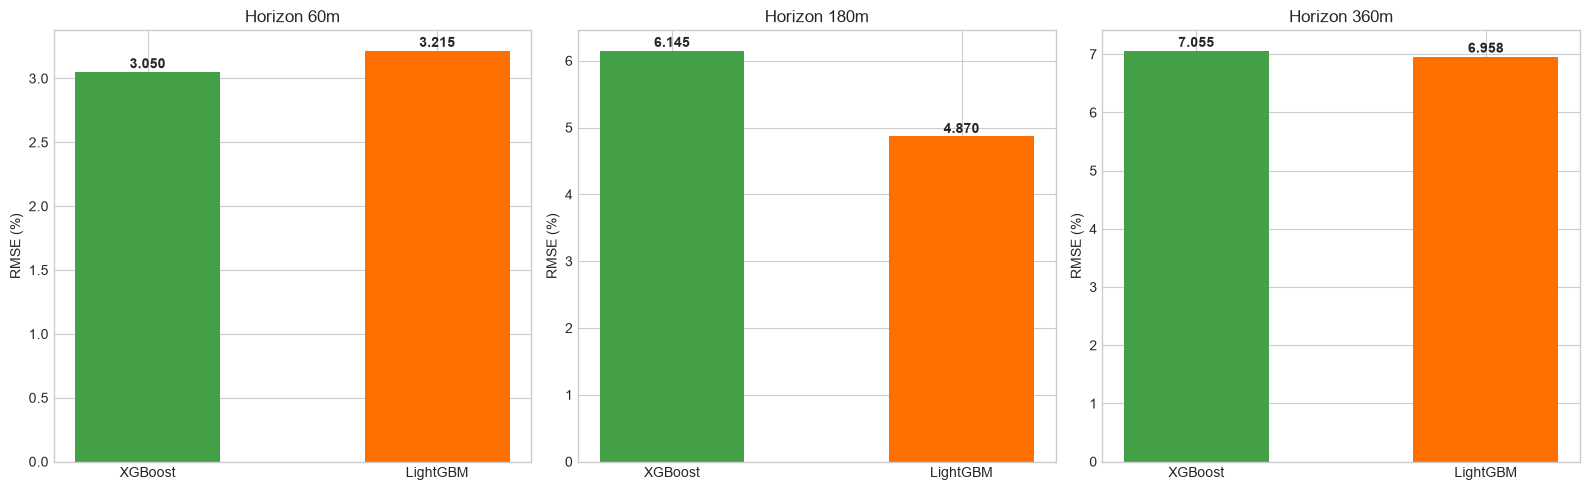

Lanjut ke 05r_evaluasi_model.ipynb


In [4]:
# -- CELL 6-7: Ringkasan & plot ------------------------------------
with open(f'{MOUT}/rf_metrics_all.json') as f: rf_results = json.load(f)
print(f'{"Horizon":<8}{"Model":<13}{"MAE":>8}{"RMSE":>8}{"R2":>8}{"MAPE":>8}')
for h in HORIZONS:
    for nama, res, key in [('RF', rf_results, 'test_metrics'), ('XGBoost', xgb_results, 'test_metrics'),
                           ('LightGBM', lgb_results, 'test_metrics'), ('Persistensi', rf_results, 'persistensi_metrics')]:
        m = res[h][key]; print(f'{h:<8}{nama:<13}{m["MAE"]:>8.3f}{m["RMSE"]:>8.3f}{m["R2"]:>8.3f}{m["MAPE"]:>8.2f}')
    print()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, h in zip(axes, HORIZONS):
    v = [xgb_results[h]['test_metrics']['RMSE'], lgb_results[h]['test_metrics']['RMSE']]
    bars = ax.bar(['XGBoost', 'LightGBM'], v, color=['#43A047', '#FF6F00'], width=0.5)
    for b, x in zip(bars, v): ax.text(b.get_x()+b.get_width()/2, x*1.01, f'{x:.3f}', ha='center', fontweight='bold')
    ax.set_title(f'Horizon {h}'); ax.set_ylabel('RMSE (%)')
plt.tight_layout(); plt.savefig(f'{OUT}/plot_xgb_lgb_rmse_revisi.png', dpi=150); plt.show()
print('Lanjut ke 05r_evaluasi_model.ipynb')